# Chapter 5: Distributions and Shape

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 5.1 What Shape Tells You

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('book.mplstyle')

In [2]:
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
tickets = pd.read_csv('support_tickets.csv',
                      parse_dates=['opened_date'])
add_ons = orders[orders['order_type'] == 'Add-on']
add_ons[['order_date', 'items', 'amount', 'delivery_days']].head()

,order_date,items,amount,delivery_days
22,2024-01-08,1,18.47,2
23,2024-01-08,1,11.19,2
48,2024-01-16,1,16.02,2
67,2024-01-19,1,16.96,2
76,2024-01-21,2,20.65,5


In [3]:
add_ons['amount'].describe().round(2)

count    4520.00
mean       25.82
std        34.68
min         4.60
25%        13.69
50%        19.26
75%        30.21
max       635.74
Name: amount, dtype: float64

## 5.2 Histograms

### `sns.histplot()`

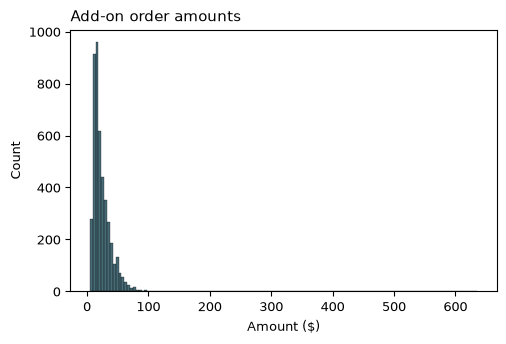

In [4]:
ax = sns.histplot(data=add_ons, x='amount')
ax.set_title('Add-on order amounts')
ax.set_xlabel('Amount ($)')
plt.show()

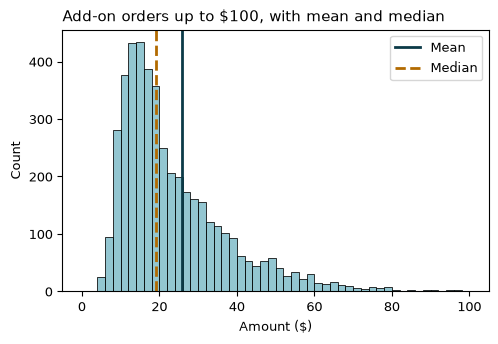

In [5]:
mean_amount = add_ons['amount'].mean()
median_amount = add_ons['amount'].median()

ax = sns.histplot(data=add_ons, x='amount', binrange=(0, 100),
                  binwidth=2, color='#6fb3c2')
ax.axvline(mean_amount, color='#0b3a47', label='Mean')
ax.axvline(median_amount, color='#b26a00', linestyle='--',
           label='Median')
ax.legend()
ax.set_title('Add-on orders up to $100, with mean and median')
ax.set_xlabel('Amount ($)')
plt.show()

### Choosing bins

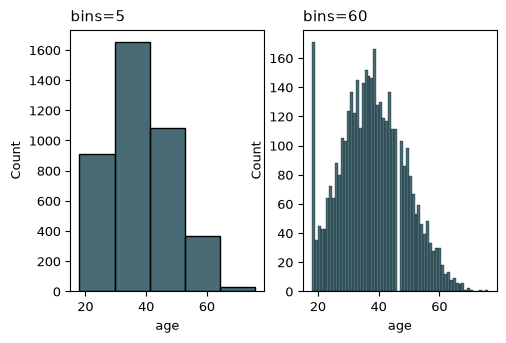

In [6]:
fig, axes = plt.subplots(1, 2)
sns.histplot(data=customers, x='age', bins=5, ax=axes[0])
sns.histplot(data=customers, x='age', bins=60, ax=axes[1])
axes[0].set_title('bins=5')
axes[1].set_title('bins=60')
plt.show()

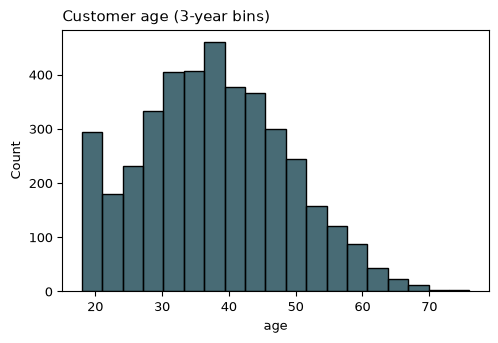

In [7]:
ax = sns.histplot(data=customers, x='age', binwidth=3)
ax.set_title('Customer age (3-year bins)')
plt.show()

In [8]:
customers['age'].value_counts().sort_index().head(4)

age
18.0    171
19.0     35
20.0     45
21.0     43
Name: count, dtype: int64

### Whole numbers with `discrete=True`

In [9]:
orders['delivery_days'].value_counts().sort_index()

delivery_days
1     3249
2     6641
3     7267
4     5639
5     3373
6     1589
7      654
8      258
9       70
10      27
11       3
12       1
13       1
Name: count, dtype: int64

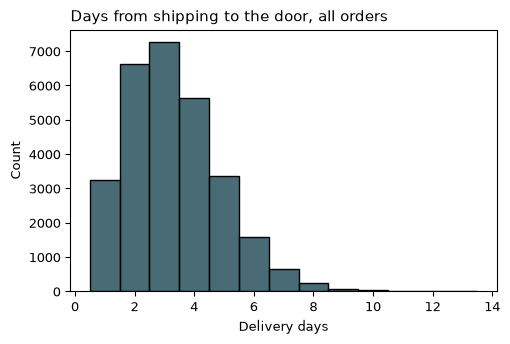

In [10]:
ax = sns.histplot(data=orders, x='delivery_days', discrete=True)
ax.set_title('Days from shipping to the door, all orders')
ax.set_xlabel('Delivery days')
plt.show()

## 5.3 Smooth Curves with KDE

### `sns.kdeplot()`

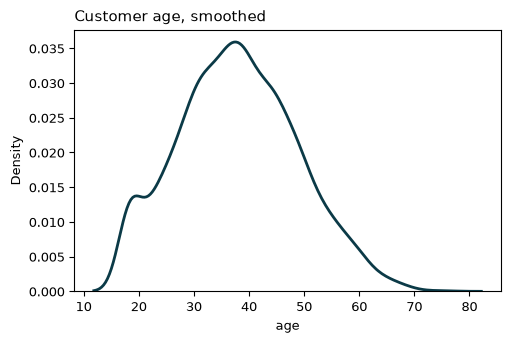

In [11]:
ax = sns.kdeplot(data=customers, x='age', color='#0b3a47')
ax.set_title('Customer age, smoothed')
plt.show()

### Bandwidth with `bw_adjust=`

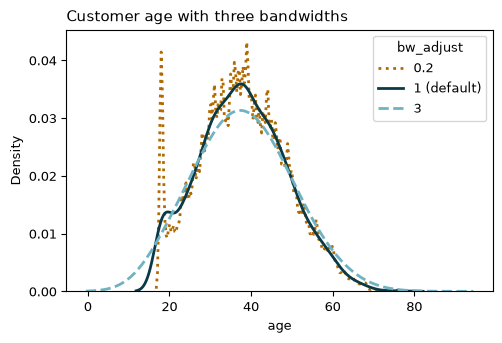

In [12]:
ax = sns.kdeplot(data=customers, x='age', bw_adjust=0.2,
                 color='#b26a00', linestyle=':', label='0.2')
sns.kdeplot(data=customers, x='age', color='#0b3a47',
            label='1 (default)', ax=ax)
sns.kdeplot(data=customers, x='age', bw_adjust=3,
            color='#6fb3c2', linestyle='--', label='3', ax=ax)
ax.legend(title='bw_adjust')
ax.set_title('Customer age with three bandwidths')
plt.show()

## 5.4 Cumulative Shares with ECDF

### `sns.ecdfplot()`

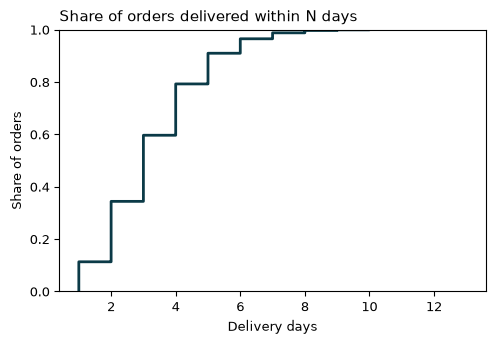

In [13]:
ax = sns.ecdfplot(data=orders, x='delivery_days', color='#0b3a47')
ax.set_title('Share of orders delivered within N days')
ax.set_xlabel('Delivery days')
ax.set_ylabel('Share of orders')
plt.show()

In [14]:
within_3 = (orders['delivery_days'] <= 3).mean()
on_time = (orders['delivery_days'] <= 5).mean()
print(f'Within 3 days: {within_3:.1%}')
print(f'Within 5 days: {on_time:.1%}')

Within 3 days: 59.6%
Within 5 days: 91.0%


### Comparing groups with `hue=`

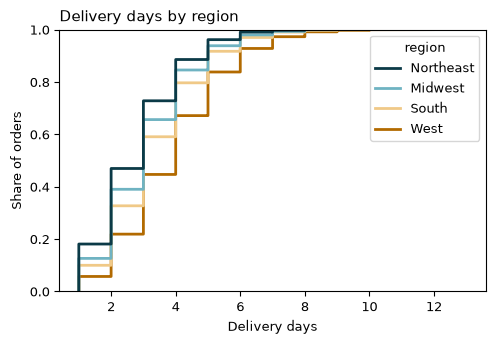

In [15]:
orders_region = orders.merge(customers[['customer_id', 'region']],
                             on='customer_id')
regions = ['Northeast', 'Midwest', 'South', 'West']

ax = sns.ecdfplot(data=orders_region, x='delivery_days',
                  hue='region', hue_order=regions,
                  palette=['#0b3a47', '#6fb3c2', '#f0c987',
                           '#b26a00'])
ax.set_title('Delivery days by region')
ax.set_xlabel('Delivery days')
ax.set_ylabel('Share of orders')
plt.show()

In [16]:
orders_region['within_3'] = orders_region['delivery_days'] <= 3
by_region = orders_region.groupby('region')['within_3'].mean()
by_region.round(3)

region
Midwest      0.656
Northeast    0.728
South        0.591
West         0.447
Name: within_3, dtype: float64

## 5.5 Box Plots

In [17]:
tickets['hours_to_resolve'].describe().round(1)

count    1380.0
mean        9.4
std        10.9
min         0.3
25%         3.2
50%         6.0
75%        11.3
max       160.2
Name: hours_to_resolve, dtype: float64

### `sns.boxplot()`

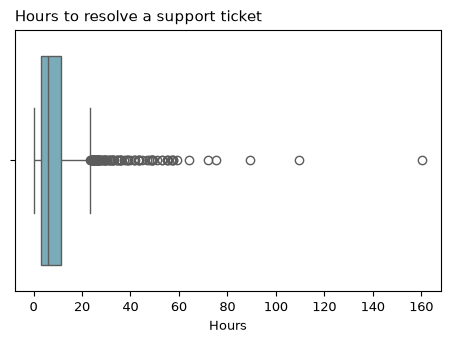

In [18]:
ax = sns.boxplot(data=tickets, x='hours_to_resolve',
                 color='#6fb3c2')
ax.set_title('Hours to resolve a support ticket')
ax.set_xlabel('Hours')
plt.show()

### Groups side by side

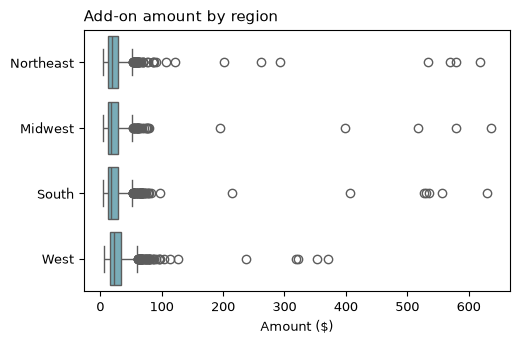

In [19]:
add_ons_region = add_ons.merge(customers[['customer_id', 'region']],
                               on='customer_id')

ax = sns.boxplot(data=add_ons_region, x='amount', y='region',
                 order=regions, color='#6fb3c2')
ax.set_title('Add-on amount by region')
ax.set_xlabel('Amount ($)')
ax.set_ylabel('')
plt.show()

## 5.6 Numbers for Shape

### `stats.describe()`

In [20]:
amount_stats = stats.describe(add_ons['amount'])
print(f'nobs:     {amount_stats.nobs}')
low, high = amount_stats.minmax
print(f'minmax:   {low} to {high}')
print(f'mean:     {amount_stats.mean:.2f}')
print(f'variance: {amount_stats.variance:.2f}')
print(f'skewness: {amount_stats.skewness:.2f}')
print(f'kurtosis: {amount_stats.kurtosis:.2f}')

nobs:     4520
minmax:   4.6 to 635.74
mean:     25.82
variance: 1202.37
skewness: 11.96
kurtosis: 175.67


In [21]:
print(f"pandas skew: {add_ons['amount'].skew():.2f}")
print(f"pandas kurt: {add_ons['amount'].kurt():.2f}")

pandas skew: 11.96
pandas kurt: 175.87


### Missing values

In [22]:
age_stats = stats.describe(customers['age'])
print(f'mean: {age_stats.mean}')

mean: nan


In [23]:
age_stats = stats.describe(customers['age'].dropna())
print(f'nobs:     {age_stats.nobs}')
print(f'mean:     {age_stats.mean:.2f}')
print(f'skewness: {age_stats.skewness:.2f}')
print(f'kurtosis: {age_stats.kurtosis:.2f}')

nobs:     4043
mean:     37.96
skewness: 0.19
kurtosis: -0.37


## 5.7 Is It Normal? Q-Q Plots

### `stats.probplot()`

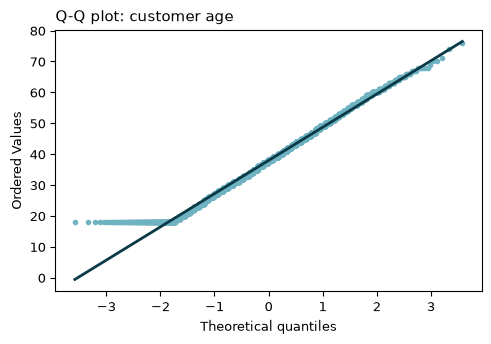

In [24]:
ages = customers['age'].dropna()

fig, ax = plt.subplots()
stats.probplot(ages, plot=ax)
ax.get_lines()[0].set(color='#6fb3c2', markersize=3)
ax.get_lines()[1].set_color('#0b3a47')
ax.set_title('Q-Q plot: customer age')
plt.show()

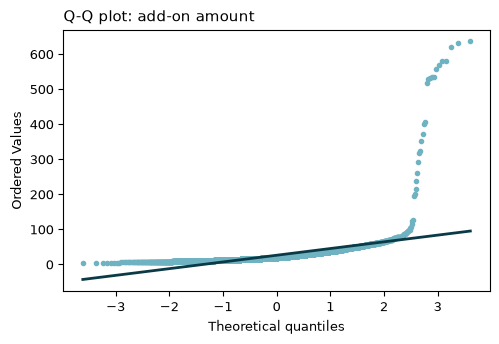

In [25]:
fig, ax = plt.subplots()
stats.probplot(add_ons['amount'], plot=ax)
ax.get_lines()[0].set(color='#6fb3c2', markersize=3)
ax.get_lines()[1].set_color('#0b3a47')
ax.set_title('Q-Q plot: add-on amount')
plt.show()

## 5.8 Taming Skew with Logs

### `np.log1p()`

In [26]:
add_ons_region['log_amount'] = np.log1p(add_ons_region['amount'])
print(f"Skew before: {add_ons_region['amount'].skew():.2f}")
print(f"Skew after:  {add_ons_region['log_amount'].skew():.2f}")

Skew before: 11.96
Skew after:  0.97


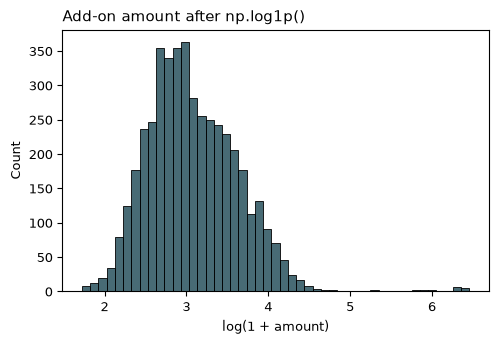

In [27]:
ax = sns.histplot(data=add_ons_region, x='log_amount', binwidth=0.1)
ax.set_title('Add-on amount after np.log1p()')
ax.set_xlabel('log(1 + amount)')
plt.show()

In [28]:
regular = add_ons_region[add_ons_region['items'] < 10]
print(f"Gift orders: {(add_ons_region['items'] >= 10).sum()}")
print(f"Skew without them: {regular['log_amount'].skew():.2f}")

Gift orders: 24
Skew without them: 0.31


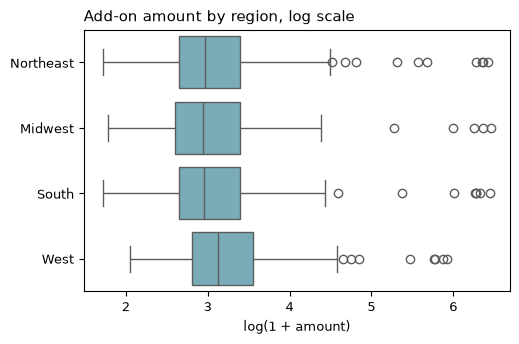

In [29]:
ax = sns.boxplot(data=add_ons_region, x='log_amount', y='region',
                 order=regions, color='#6fb3c2')
ax.set_title('Add-on amount by region, log scale')
ax.set_xlabel('log(1 + amount)')
ax.set_ylabel('')
plt.show()

### Back to dollars with `np.expm1()`

In [30]:
log_medians = add_ons_region.groupby('region')['log_amount'].median()
np.expm1(log_medians).round(2)

region
Midwest      17.97
Northeast    18.51
South        18.19
West         21.83
Name: log_amount, dtype: float64